# Lab 11 – Text Visualization and Sentiment Analysis

## Setup and dataset inspection

In [ ]:
!pip -q install wordcloud vaderSentiment nltk scikit-learn seaborn
import os, re, html, warnings
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from nltk.stem import PorterStemmer, WordNetLemmatizer
import nltk
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,5)

if not os.path.exists("Tweets.csv"):
    from google.colab import files
    uploaded = files.upload()
    csv_file = next((f for f in uploaded if f.lower().endswith(".csv")), None)
    if csv_file is None: raise FileNotFoundError("Upload Tweets.csv")
else: csv_file = "Tweets.csv"
df = pd.read_csv(csv_file)
print("Shape:", df.shape)
print(df.columns.tolist())
display(df.head())
display(df.isna().sum().to_frame("Missing values"))
display(df["airline_sentiment"].value_counts().to_frame("Tweet count"))
display(df["airline"].value_counts().to_frame("Tweet count"))
df["tweet_created"] = pd.to_datetime(df["tweet_created"], errors="coerce", utc=True)

Shape: (14640, 15)
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


,Missing values
tweet_id,0
airline_sentiment,0
airline_sentiment_confidence,0
negativereason,5462
negativereason_confidence,4118
airline,0
airline_sentiment_gold,14600
name,0
negativereason_gold,14608
retweet_count,0


,Tweet count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


,Tweet count
airline,
United,3822
US Airways,2913
American,2759
Southwest,2420
Delta,2222
Virgin America,504


# Part A – Text cleaning and preprocessing
## Task 1. Twitter features and naive tokenization
Inspect handles, hashtags, links, emojis, HTML entities and stretched words. Compare naive splitting with a cleaning/tokenization approach.

In [ ]:
examples = [
 "@VirginAmerica I LOVE this flight!!!",
 "Thanks #airline for the great service 😊",
 "My flight is sooo delayed :( https://example.com",
 "I didn't enjoy it &amp; won't fly again."
]
for x in examples:
    print("\nOriginal:", x)
    print("Naive split:", x.split())

def normalize_tweet(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"(\w)\1{2,}", r"\1\1", text)
    text = re.sub(r"[^a-zA-Z'\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", normalize_tweet(text))
for x in examples:
    print("Normalized:", normalize_tweet(x), "| tokens:", tokenize(x))
print("Decision: remove handles/URLs from word counts, retain hashtag words, normalize stretched spellings, decode HTML entities. Preserve original text for sentiment scoring; emojis can carry sentiment and are not included in the word-only tokens.")


Original: @VirginAmerica I LOVE this flight!!!
Naive split: ['@VirginAmerica', 'I', 'LOVE', 'this', 'flight!!!']

Original: Thanks #airline for the great service 😊
Naive split: ['Thanks', '#airline', 'for', 'the', 'great', 'service', '😊']

Original: My flight is sooo delayed :( https://example.com
Naive split: ['My', 'flight', 'is', 'sooo', 'delayed', ':(', 'https://example.com']

Original: I didn't enjoy it &amp; won't fly again.
Naive split: ['I', "didn't", 'enjoy', 'it', '&amp;', "won't", 'fly', 'again.']
Normalized: i love this flight | tokens: ['i', 'love', 'this', 'flight']
Normalized: thanks airline for the great service | tokens: ['thanks', 'airline', 'for', 'the', 'great', 'service']
Normalized: my flight is soo delayed | tokens: ['my', 'flight', 'is', 'soo', 'delayed']
Normalized: i didn't enjoy it won't fly again | tokens: ['i', "didn't", 'enjoy', 'it', "won't", 'fly', 'again']
Decision: remove handles/URLs from word counts, retain hashtag words, normalize stretched spellin

## Task 2. Stop words and negation
Compare removing a standard stop list with a custom list that keeps `not`, `no`, `nor`, and negation contractions.

In [ ]:
BASIC_STOPWORDS = set("""
a an the and or but if while of at by for with about against between into through
during before after above below to from up down in out on off over under again
further then once here there when where why how all any both each few more most
other some such only own same so than too very can will just should now i me my
we our ours you your yours he him his she her it its they them their what which
who this that these those am is are was were be been being have has had having
do does did doing as until because
""".split())
NEGATIONS = {"not","no","nor","never"}
CUSTOM_STOPWORDS = BASIC_STOPWORDS - NEGATIONS
def remove_stops(tokens, stopwords): return [w for w in tokens if w not in stopwords]
samples = ["The flight was good", "The flight was not good", "No help from customer service", "I will never fly again"]
analyzer = SentimentIntensityAnalyzer()
for x in samples:
    t = tokenize(x)
    print(x, "| standard:", remove_stops(t, BASIC_STOPWORDS),
          "| negation kept:", remove_stops(t, CUSTOM_STOPWORDS),
          "| VADER compound:", analyzer.polarity_scores(x)["compound"])
print("Decision: protect negation words because removing them can reverse meaning. Use the custom list for frequency analysis.")

The flight was good | standard: ['flight', 'good'] | negation kept: ['flight', 'good'] | VADER compound: 0.4404
The flight was not good | standard: ['flight', 'not', 'good'] | negation kept: ['flight', 'not', 'good'] | VADER compound: -0.3412
No help from customer service | standard: ['no', 'help', 'customer', 'service'] | negation kept: ['no', 'help', 'customer', 'service'] | VADER compound: -0.3089
I will never fly again | standard: ['never', 'fly'] | negation kept: ['never', 'fly'] | VADER compound: 0.0
Decision: protect negation words because removing them can reverse meaning. Use the custom list for frequency analysis.


## Task 3. Stemming versus lemmatization
Apply both methods to the same vocabulary and compare vocabulary size before and after.

,Word,Stem,Lemma
0,delayed,delay,delayed
1,delays,delay,delay
2,cancellations,cancel,cancellation
3,cancelled,cancel,cancelled
4,flying,fli,flying
5,flies,fli,fly
6,services,servic,service
7,better,better,better
8,worst,worst,worst
9,running,run,running


,Method,Unique vocabulary
0,Original,11318
1,Porter stemming,8631
2,WordNet lemmatization,10407


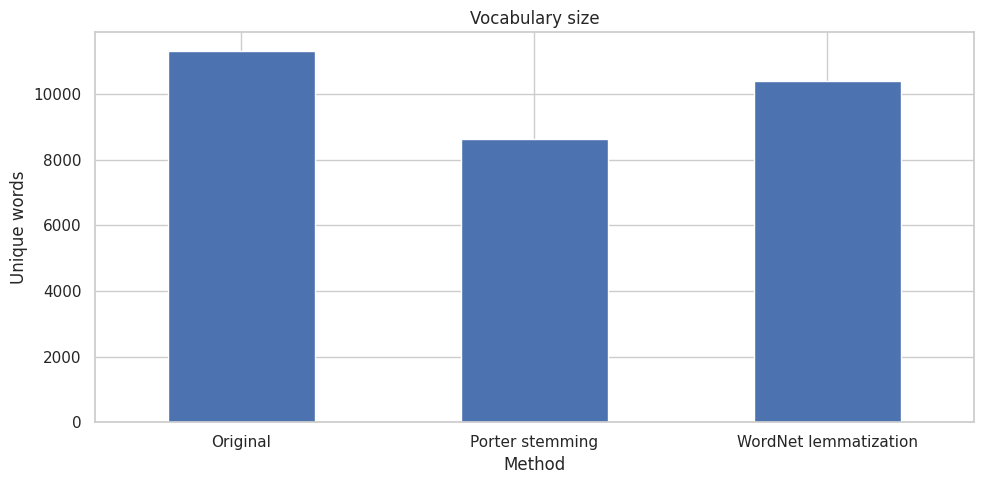

Stemming is more aggressive and may create fragments. Lemmatization is usually more readable; this WordNet version has no POS tagging, which limits accuracy.


In [ ]:
stemmer, lemmatizer = PorterStemmer(), WordNetLemmatizer()
vocab_examples = ["delayed","delays","cancellations","cancelled","flying","flies","services","better","worst","running","friendly"]
display(pd.DataFrame({"Word":vocab_examples,
 "Stem":[stemmer.stem(w) for w in vocab_examples],
 "Lemma":[lemmatizer.lemmatize(w) for w in vocab_examples]}))
all_tokens = [w for x in df["text"].fillna("") for w in tokenize(x)]
vocab_compare = pd.DataFrame({"Method":["Original","Porter stemming","WordNet lemmatization"],
 "Unique vocabulary":[len(set(all_tokens)),len({stemmer.stem(w) for w in all_tokens}),len({lemmatizer.lemmatize(w) for w in all_tokens})]})
display(vocab_compare)
vocab_compare.set_index("Method").plot(kind="bar",legend=False,title="Vocabulary size",rot=0); plt.ylabel("Unique words"); plt.tight_layout(); plt.show()
print("Stemming is more aggressive and may create fragments. Lemmatization is usually more readable; this WordNet version has no POS tagging, which limits accuracy.")

## Task 4. Cost of each cleaning step
Measure vocabulary size, average tweet length and tweets left empty after each stage.

,Step,Vocabulary size,Average tweet length,Tweets left empty,Empty tweets (%)
0,Raw tokens,15089,18.35,0,0.00
1,URLs/handles removed and normalized,11318,16.04,0,0.00
2,Standard stop words removed,11208,9.20,20,0.14
3,Custom stop words removed,11208,9.20,20,0.14


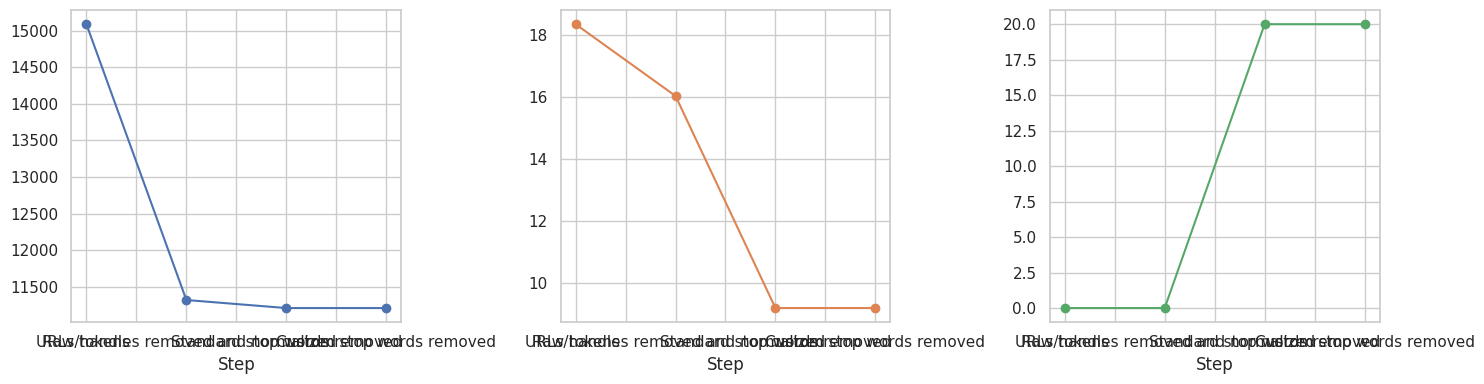

In [ ]:
raw = df["text"].fillna("").astype(str)
steps = {
 "Raw tokens":[re.findall(r"\b\w+\b",x.lower()) for x in raw],
 "URLs/handles removed and normalized":[tokenize(x) for x in raw],
 "Standard stop words removed":[remove_stops(tokenize(x),BASIC_STOPWORDS) for x in raw],
 "Custom stop words removed":[remove_stops(tokenize(x),CUSTOM_STOPWORDS) for x in raw]
}
rows=[]
for name, lists in steps.items():
    flat=[w for row in lists for w in row]; lens=[len(row) for row in lists]
    rows.append([name,len(set(flat)),np.mean(lens),sum(n==0 for n in lens),100*np.mean(np.array(lens)==0)])
cleaning_cost=pd.DataFrame(rows,columns=["Step","Vocabulary size","Average tweet length","Tweets left empty","Empty tweets (%)"])
display(cleaning_cost.round(2))
cleaning_cost.set_index("Step")[["Vocabulary size","Average tweet length","Tweets left empty"]].plot(subplots=True,layout=(1,3),figsize=(15,4),marker="o",legend=False)
plt.tight_layout(); plt.show()

# Part B – Meaningful words and phrases
## Task 5. Airline names and generic filler

,Word,Count
0,to,8653
1,i,6722
2,the,6064
3,a,4622
4,you,4401
5,united,4167
6,for,4001
7,flight,3958
8,on,3816
9,and,3733


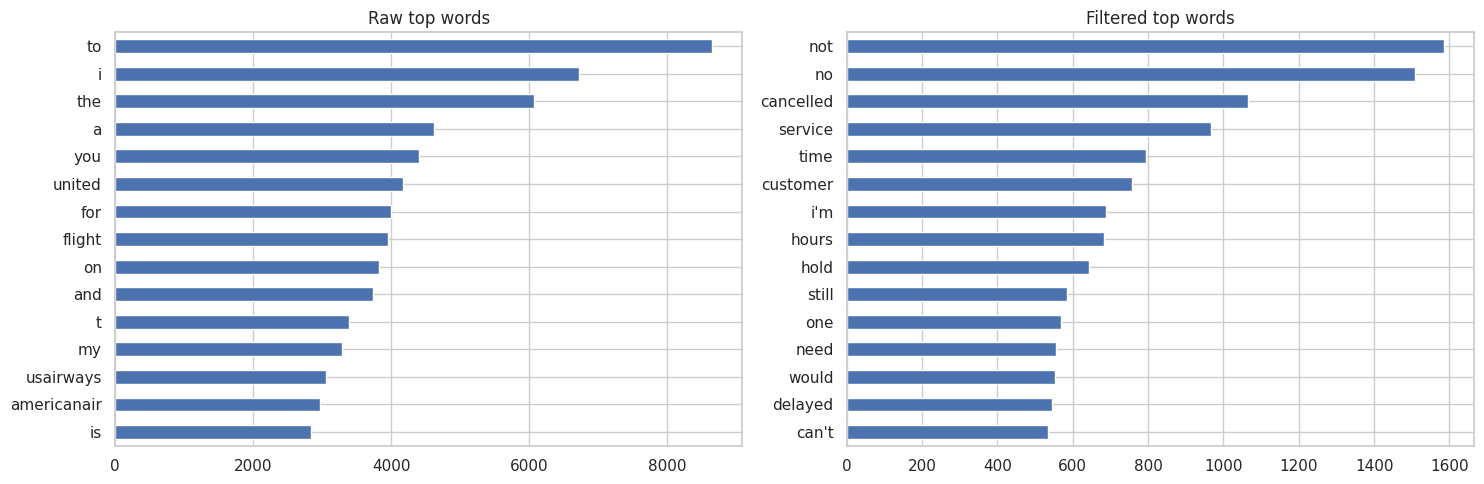

Airline names can dominate because users address airline accounts and the collection targets airline-related tweets.


In [ ]:
raw_counter=Counter(w for x in raw for w in re.findall(r"[a-z]+",html.unescape(x.lower())))
display(pd.DataFrame(raw_counter.most_common(25),columns=["Word","Count"]))
airline_terms=set()
for a in df["airline"].dropna().unique(): airline_terms.update(re.findall(r"[a-z]+",a.lower()))
generic=set("flight flights airline airlines plane just get got thanks thank please help".split())
excluded=BASIC_STOPWORDS|airline_terms|generic
clean_counter=Counter(w for x in raw for w in remove_stops(tokenize(x),excluded))
fig,ax=plt.subplots(1,2,figsize=(15,5))
pd.Series(dict(raw_counter.most_common(15))).sort_values().plot.barh(ax=ax[0],title="Raw top words")
pd.Series(dict(clean_counter.most_common(15))).sort_values().plot.barh(ax=ax[1],title="Filtered top words")
plt.tight_layout(); plt.show()
print("Airline names can dominate because users address airline accounts and the collection targets airline-related tweets.")

## Task 6. Distinctive positive and negative words using TF-IDF

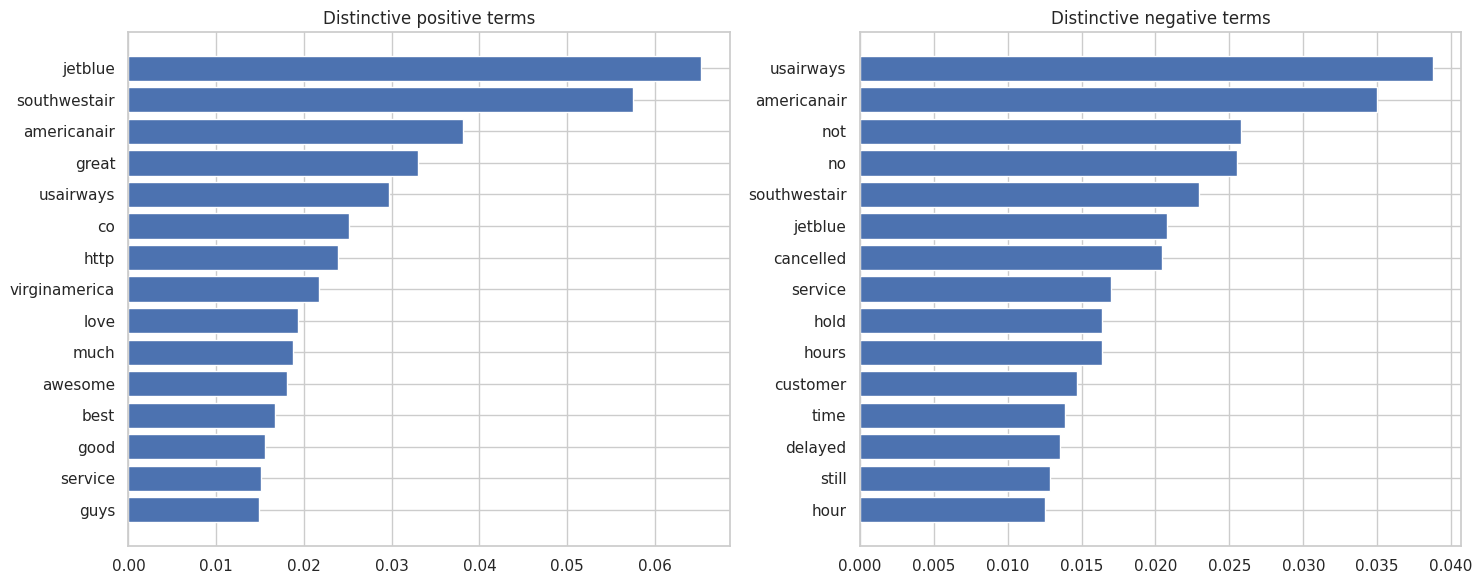

Raw frequency alone fails when a word is common in both groups. TF-IDF gives more weight to terms that are distinctive within a group.


In [ ]:
sent=df["airline_sentiment"].astype(str).str.lower()
pos=raw[sent.eq("positive")]; neg=raw[sent.eq("negative")]
vectorizer=TfidfVectorizer(stop_words=list(CUSTOM_STOPWORDS|airline_terms|generic),
 token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b",max_features=5000,min_df=3)
mat=vectorizer.fit_transform(pd.concat([pos,neg],ignore_index=True))
terms=np.array(vectorizer.get_feature_names_out())
p=np.asarray(mat[:len(pos)].mean(axis=0)).ravel()
n=np.asarray(mat[len(pos):].mean(axis=0)).ravel()
fig,ax=plt.subplots(1,2,figsize=(15,6))
for a,vals,title in [(ax[0],p,"Distinctive positive terms"),(ax[1],n,"Distinctive negative terms")]:
    ix=np.argsort(vals)[-15:]; a.barh(terms[ix],vals[ix]); a.set_title(title)
plt.tight_layout(); plt.show()
print("Raw frequency alone fails when a word is common in both groups. TF-IDF gives more weight to terms that are distinctive within a group.")

## Task 7. Negative bigrams and trigrams

,Phrase,Count
19,customer service,450
18,cancelled flightled,448
17,http co,437
16,late flight,221
15,cancelled flighted,204
14,flight cancelled,199
13,late flightr,145
12,no one,125
11,cancelled flight,124
10,flight delayed,117


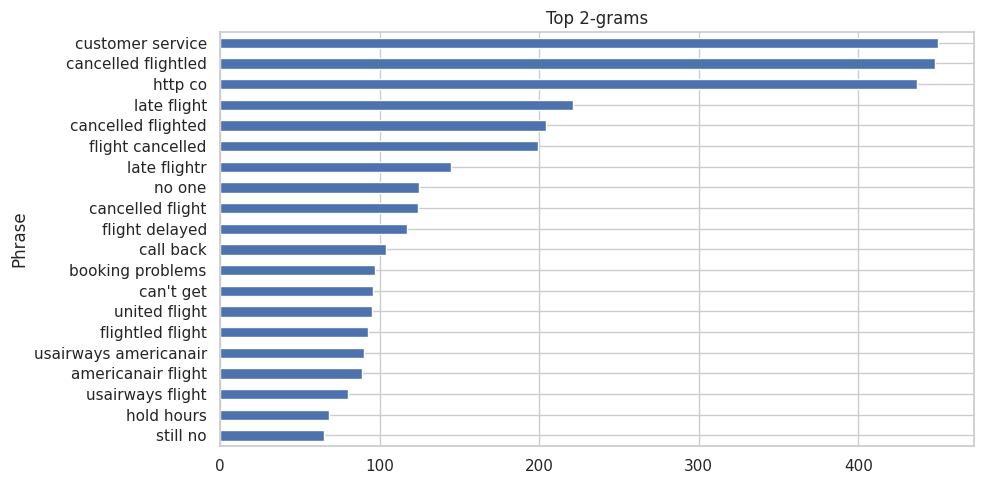

,Phrase,Count
19,flight cancelled flightled,128
18,cancelled flightled flight,93
17,flight booking problems,56
16,flight cancelled flighted,51
15,cancelled flight flight,42
14,cancelled flighted flight,41
13,worst customer service,40
12,reflight booking problems,38
11,hours late flightr,33
9,jetblue fleet's fleek,29


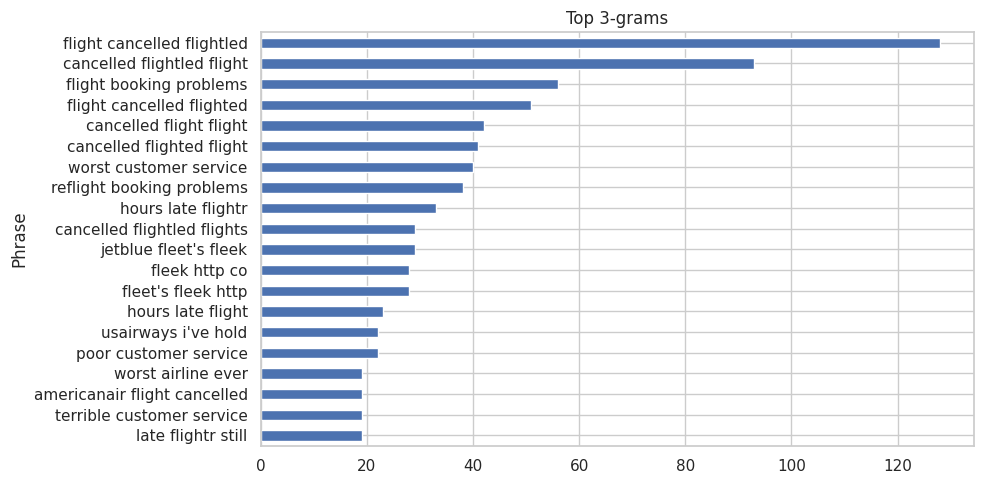

not good -0.3412
not bad 0.431
never again 0.0
no problem 0.3089
Use the phrase tables to identify operational problems and inspect the original tweets. Negation phrases show how a pair can change meaning.


In [ ]:
negative_texts=raw[sent.eq("negative")].tolist()
def ngram_table(texts,ngram_range,top=20):
    v=CountVectorizer(stop_words=list(CUSTOM_STOPWORDS),ngram_range=ngram_range,
      token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b",min_df=2)
    m=v.fit_transform(texts); counts=np.asarray(m.sum(axis=0)).ravel(); words=np.array(v.get_feature_names_out())
    ix=np.argsort(counts)[-top:]
    out=pd.DataFrame({"Phrase":words[ix],"Count":counts[ix]}).sort_values("Count",ascending=False)
    display(out); out.sort_values("Count").plot(x="Phrase",y="Count",kind="barh",legend=False,title=f"Top {ngram_range[0]}-grams")
    plt.tight_layout(); plt.show(); return out
bigrams=ngram_table(negative_texts,(2,2))
trigrams=ngram_table(negative_texts,(3,3))
for phrase in ["not good","not bad","never again","no problem"]:
    print(phrase,analyzer.polarity_scores(phrase)["compound"])
print("Use the phrase tables to identify operational problems and inspect the original tweets. Negation phrases show how a pair can change meaning.")

## Task 8. Word cloud versus bar chart

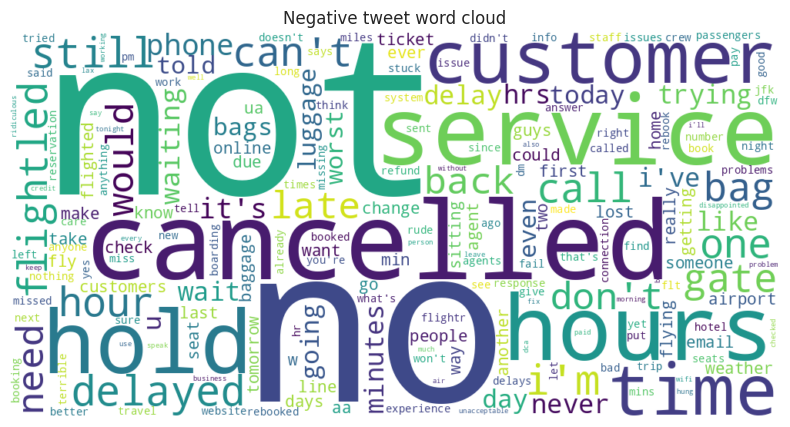

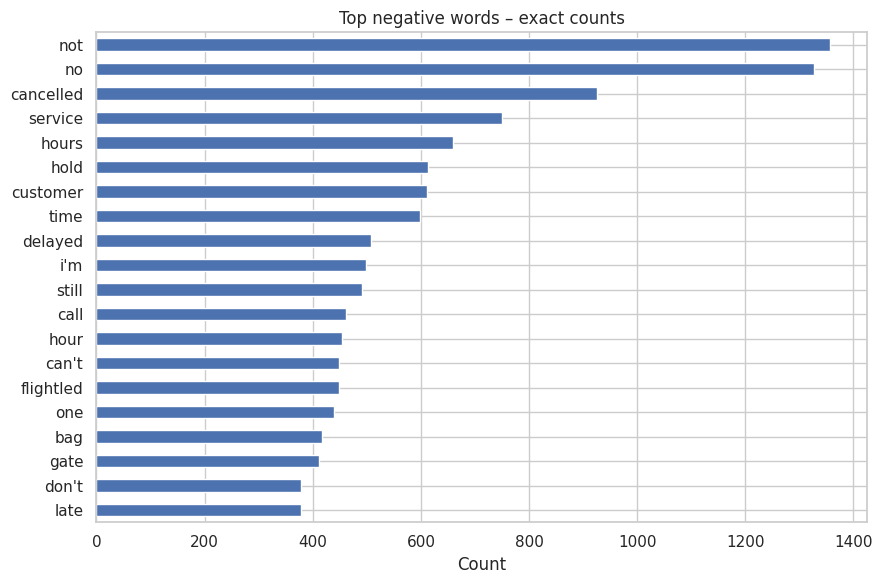

Recommendation: show the bar chart to the Director because exact counts and comparisons are easier to read. The word cloud is a quick overview, not a precise comparison.


In [ ]:
neg_tokens=[w for x in negative_texts for w in remove_stops(tokenize(x),excluded)]
neg_counts=Counter(neg_tokens)
if neg_counts:
    cloud=WordCloud(width=1000,height=500,background_color="white",collocations=False).generate_from_frequencies(neg_counts)
    plt.figure(figsize=(12,5)); plt.imshow(cloud,interpolation="bilinear"); plt.axis("off"); plt.title("Negative tweet word cloud"); plt.show()
    pd.Series(dict(neg_counts.most_common(20))).sort_values().plot.barh(figsize=(9,6),title="Top negative words – exact counts")
    plt.xlabel("Count"); plt.tight_layout(); plt.show()
print("Recommendation: show the bar chart to the Director because exact counts and comparisons are easier to read. The word cloud is a quick overview, not a precise comparison.")

# Part C – Sentiment evaluation
## Task 9. VADER versus human labels

Overall accuracy: 0.4899
              precision    recall  f1-score   support

    negative       0.90      0.44      0.59      9178
     neutral       0.39      0.32      0.35      3099
    positive       0.28      0.91      0.43      2363

    accuracy                           0.49     14640
   macro avg       0.52      0.56      0.46     14640
weighted avg       0.69      0.49      0.51     14640



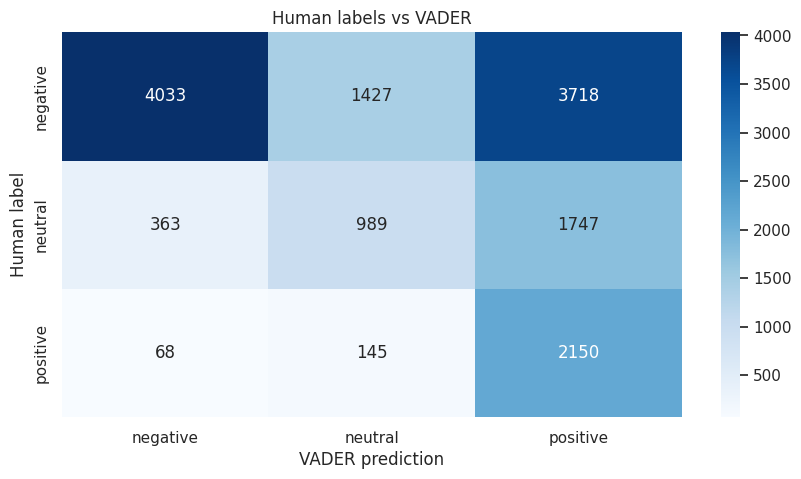

,Recall
negative,0.439420
neutral,0.319135
positive,0.909860


The lowest recall identifies the class VADER finds hardest.


In [ ]:
scores=raw.apply(analyzer.polarity_scores)
df["vader_compound"]=scores.apply(lambda x:x["compound"])
df["vader_sentiment"]=df["vader_compound"].apply(lambda x:"positive" if x>=.05 else ("negative" if x<=-.05 else "neutral"))
valid=df["airline_sentiment"].isin(["negative","neutral","positive"])
y=df.loc[valid,"airline_sentiment"]; pred=df.loc[valid,"vader_sentiment"]
print("Overall accuracy:",round(accuracy_score(y,pred),4))
print(classification_report(y,pred,zero_division=0))
labels=["negative","neutral","positive"]; cm=confusion_matrix(y,pred,labels=labels)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=labels,yticklabels=labels)
plt.xlabel("VADER prediction"); plt.ylabel("Human label"); plt.title("Human labels vs VADER"); plt.show()
class_recall=pd.Series(np.diag(cm)/np.maximum(cm.sum(axis=1),1),index=labels,name="Recall")
display(class_recall.to_frame())
print("The lowest recall identifies the class VADER finds hardest.")

## Task 10. Disagreement examples and likely causes
Cause labels below are heuristic keyword groups, not verified human annotations.

,Tweet count
cause,
Other/context,4061
Negation,2364
Airline operational vocabulary,618
Mixed feelings,399
Sarcasm,26


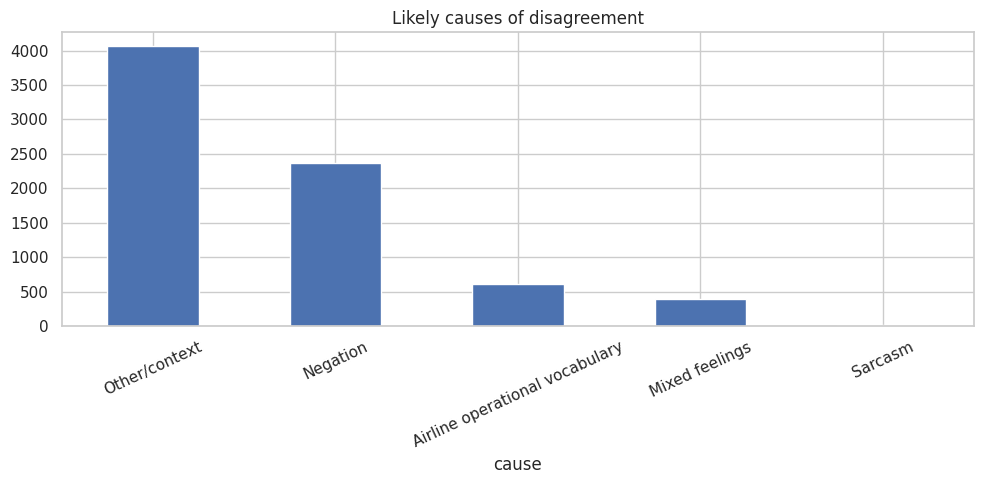

Largest heuristic cause: Other/context


,text,airline_sentiment,vader_sentiment,vader_compound,cause
1,@VirginAmerica plus you've added commercials t...,positive,neutral,0.0000,Other/context
7,@VirginAmerica Really missed a prime opportuni...,neutral,positive,0.0790,Negation
10,@VirginAmerica did you know that suicide is th...,neutral,negative,-0.8555,Other/context
16,@VirginAmerica So excited for my first cross c...,positive,negative,-0.5566,Mixed feelings
17,@VirginAmerica I flew from NYC to SFO last we...,negative,positive,0.5754,Negation
20,@VirginAmerica why are your first fares in May...,negative,neutral,0.0000,Other/context
23,@VirginAmerica will you be making BOS&gt;LAS n...,neutral,negative,-0.2960,Other/context
24,@VirginAmerica you guys messed up my seating.....,negative,positive,0.6486,Other/context
27,@VirginAmerica do you miss me? Don't worry we'...,neutral,positive,0.2037,Negation
28,@VirginAmerica amazing to me that we can't get...,negative,positive,0.5859,Negation


Potential fixes: add airline-specific terms, preserve negation scope, detect contrast, and send ambiguous/sarcastic tweets to human review.


In [ ]:
disagreements=df.loc[valid & (df["airline_sentiment"]!=df["vader_sentiment"])].copy()
sarcasm=["yeah right","great job","thanks for nothing","love waiting","just great"]
negation=["not ","no ","never ","n't","hardly","without"]
mixed=["but","however","although","though","yet"]
operations=["delayed","delay","cancelled","canceled","cancellation","baggage","lost bag","missed connection"]
def cause(t):
    t=str(t).lower()
    if any(z in t for z in sarcasm): return "Sarcasm"
    if any(z in t for z in negation): return "Negation"
    if any(z in t for z in operations): return "Airline operational vocabulary"
    if any(z in t for z in mixed): return "Mixed feelings"
    return "Other/context"
disagreements["cause"]=disagreements["text"].apply(cause)
cause_counts=disagreements["cause"].value_counts()
display(cause_counts.to_frame("Tweet count"))
cause_counts.plot.bar(title="Likely causes of disagreement",rot=25); plt.tight_layout(); plt.show()
print("Largest heuristic cause:",cause_counts.index[0] if len(cause_counts) else "None")
display(disagreements[["text","airline_sentiment","vader_sentiment","vader_compound","cause"]].head(25))
print("Potential fixes: add airline-specific terms, preserve negation scope, detect contrast, and send ambiguous/sarcastic tweets to human review.")

## Task 11. Three original example tweets

In [ ]:
examples=pd.DataFrame({
 "Tweet":[
 "Great, another three-hour delay. Just what I needed.",
 "I thought service would be awful, but the crew was wonderful.",
 "The flight was not bad, and the staff were not unhelpful."
 ],
 "Expected interpretation":[
 "Negative sarcasm despite positive word 'Great'",
 "Mixed wording; positive overall despite 'awful'",
 "Mildly positive; negation changes meaning"
 ]})
examples["VADER compound"]=examples["Tweet"].apply(lambda x:analyzer.polarity_scores(x)["compound"])
examples["VADER class"]=examples["VADER compound"].apply(lambda x:"positive" if x>=.05 else ("negative" if x<=-.05 else "neutral"))
display(examples)
print("These are constructed examples, not observations from the CSV. Discuss where VADER's score does or does not match the intended meaning.")

,Tweet,Expected interpretation,VADER compound,VADER class
0,"Great, another three-hour delay. Just what I n...",Negative sarcasm despite positive word 'Great',0.4215,positive
1,"I thought service would be awful, but the crew...",Mixed wording; positive overall despite 'awful',0.6187,positive
2,"The flight was not bad, and the staff were not...",Mildly positive; negation changes meaning,0.4310,positive


These are constructed examples, not observations from the CSV. Discuss where VADER's score does or does not match the intended meaning.


## Task 12. High-confidence human labels

In [ ]:
if "airline_sentiment_confidence" in df.columns:
    high=valid & (df["airline_sentiment_confidence"]>=.80)
    print("All labelled:",int(valid.sum()),"High-confidence >= .80:",int(high.sum()))
    print("All-label accuracy:",round(accuracy_score(df.loc[valid,"airline_sentiment"],df.loc[valid,"vader_sentiment"]),4))
    print("High-confidence accuracy:",round(accuracy_score(df.loc[high,"airline_sentiment"],df.loc[high,"vader_sentiment"]),4))
    print(classification_report(df.loc[high,"airline_sentiment"],df.loc[high,"vader_sentiment"],zero_division=0))
else: print("Confidence column not present.")

All labelled: 14640 High-confidence >= .80: 10459
All-label accuracy: 0.4899
High-confidence accuracy: 0.5313
              precision    recall  f1-score   support

    negative       0.95      0.48      0.64      7392
     neutral       0.34      0.37      0.35      1550
    positive       0.29      0.94      0.44      1517

    accuracy                           0.53     10459
   macro avg       0.52      0.60      0.48     10459
weighted avg       0.76      0.53      0.57     10459



# Part D – Airline comparison and action priorities
## Task 13. Complaint mix by airline

negativereason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Lost Luggage,longlines
airline,,,,,,,,,,
American,87,198,246,768,12,87,130,249,149,34
Delta,64,186,51,199,11,60,44,269,57,14
Southwest,90,159,162,391,14,38,61,152,90,29
US Airways,104,246,189,811,11,123,122,453,154,50
United,216,379,181,681,22,168,144,525,269,48
Virgin America,19,22,18,60,4,5,28,17,5,3


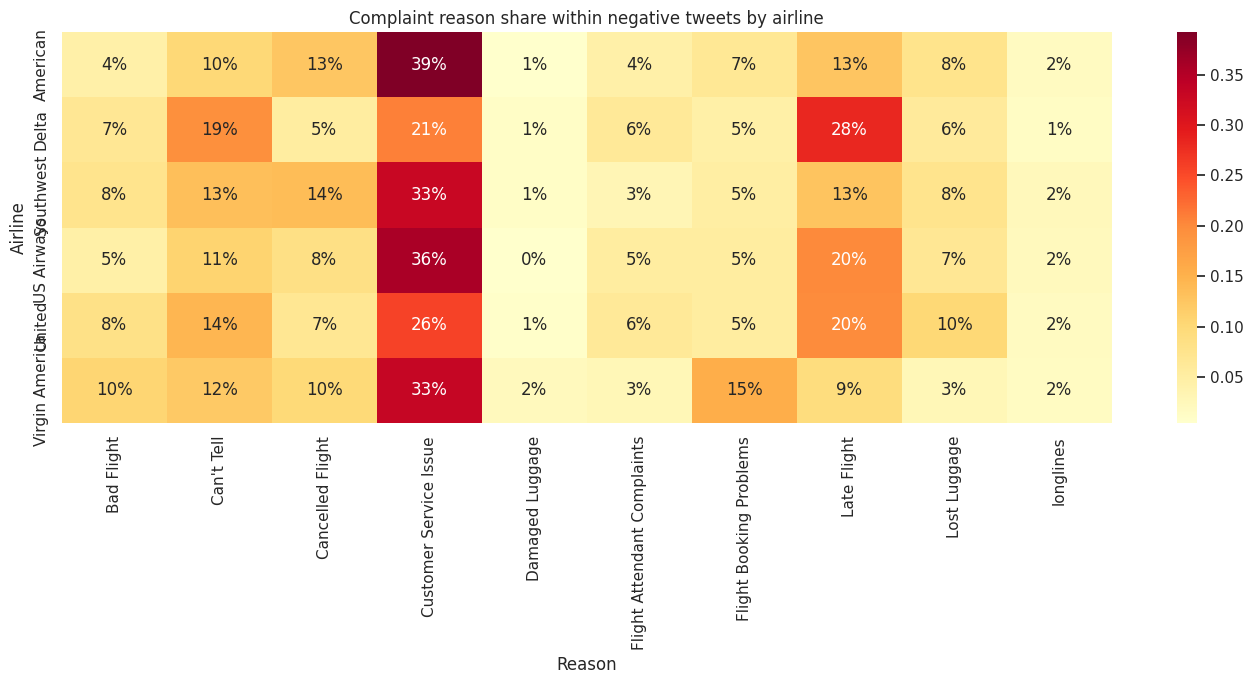

Use the complaint mix to test the service-versus-operations hypothesis descriptively; it does not prove causation.


In [ ]:
negative_df=df[df["airline_sentiment"].eq("negative")].copy()
reason_counts=pd.crosstab(negative_df["airline"],negative_df["negativereason"])
reason_share=reason_counts.div(reason_counts.sum(axis=1),axis=0)
display(reason_counts)
plt.figure(figsize=(14,7)); sns.heatmap(reason_share,annot=True,fmt=".0%",cmap="YlOrRd")
plt.title("Complaint reason share within negative tweets by airline"); plt.xlabel("Reason"); plt.ylabel("Airline"); plt.tight_layout(); plt.show()
print("Use the complaint mix to test the service-versus-operations hypothesis descriptively; it does not prove causation.")

## Task 14. Raw negative counts versus negative share

,Total_tweets,Negative_tweets,Negative_share
airline,,,
United,3822,2633,0.689
US Airways,2913,2263,0.777
American,2759,1960,0.710
Southwest,2420,1186,0.490
Delta,2222,955,0.430
Virgin America,504,181,0.359


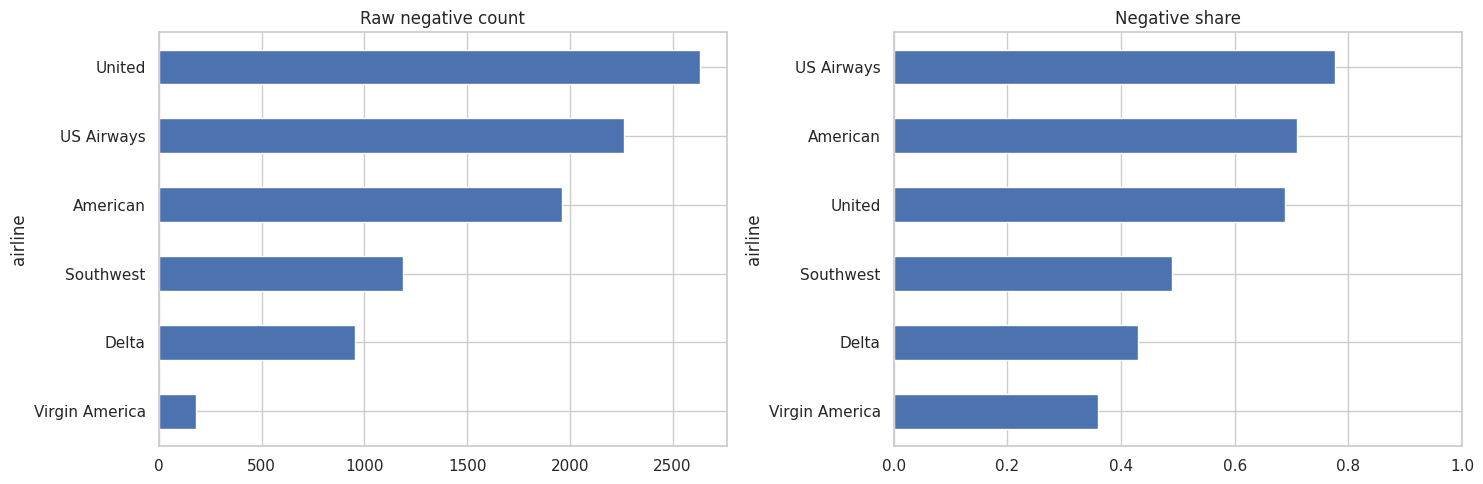

Largest difference between count/share ranking: United


,Total_tweets,Negative_tweets,Negative_share
airline,,,
United,3822,2633,0.689


Report both count and share; use share for relative comparison and count for workload.


In [ ]:
airline_summary=df.groupby("airline").agg(
 Total_tweets=("tweet_id","count"),
 Negative_tweets=("airline_sentiment",lambda x:(x=="negative").sum()))
airline_summary["Negative_share"]=airline_summary["Negative_tweets"]/airline_summary["Total_tweets"]
display(airline_summary.sort_values("Negative_tweets",ascending=False).round(3))
fig,ax=plt.subplots(1,2,figsize=(15,5))
airline_summary["Negative_tweets"].sort_values().plot.barh(ax=ax[0],title="Raw negative count")
airline_summary["Negative_share"].sort_values().plot.barh(ax=ax[1],title="Negative share",xlim=(0,1))
plt.tight_layout(); plt.show()
rr=airline_summary["Negative_tweets"].rank(ascending=False); sr=airline_summary["Negative_share"].rank(ascending=False)
diff=(rr-sr).abs().sort_values()
print("Largest difference between count/share ranking:",diff.index[-1])
display(airline_summary.loc[[diff.index[-1]]].round(3))
print("Report both count and share; use share for relative comparison and count for workload.")

## Task 15. Negative sentiment over time

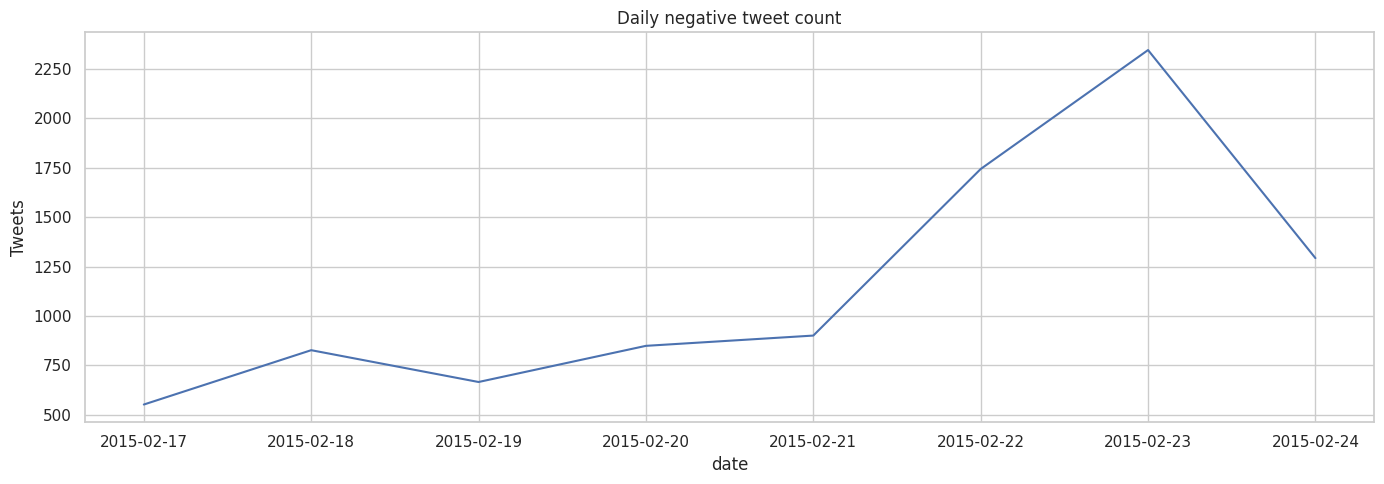

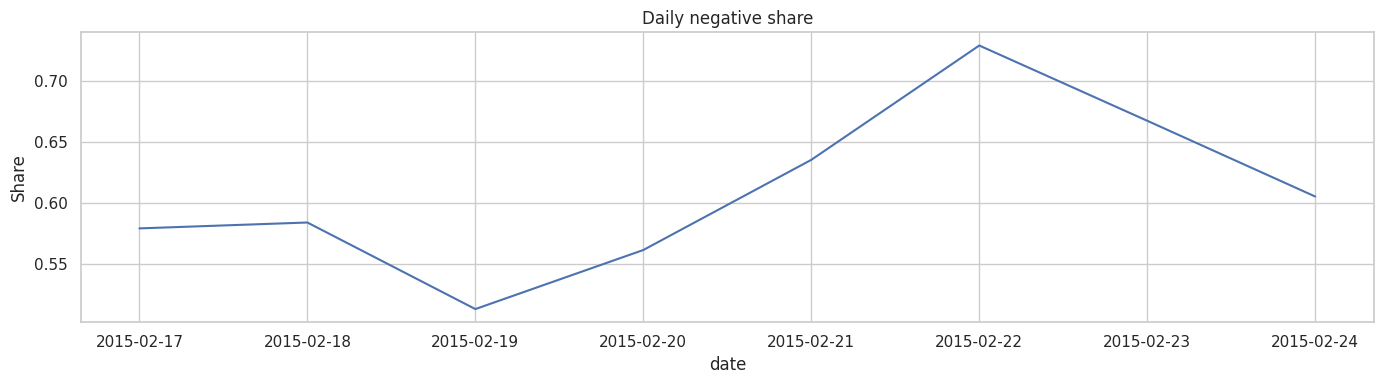

,total,negative,negative_share
date,,,
2015-02-23,3515,2346,0.667425
2015-02-22,2392,1744,0.729097
2015-02-24,2136,1293,0.605337
2015-02-21,1418,901,0.635402
2015-02-20,1512,849,0.561508
2015-02-18,1416,827,0.584040
2015-02-19,1298,666,0.513097
2015-02-17,953,552,0.579224


Spikes are observed in this sample; the short 2015 window does not establish their cause.


In [ ]:
dated=df.dropna(subset=["tweet_created"]).copy()
dated["date"]=dated["tweet_created"].dt.date
dated["is_negative"]=dated["airline_sentiment"].eq("negative")
daily=dated.groupby("date").agg(total=("tweet_id","count"),negative=("is_negative","sum"))
daily["negative_share"]=daily["negative"]/daily["total"]
daily["negative"].plot(figsize=(14,5),title="Daily negative tweet count",ylabel="Tweets"); plt.tight_layout(); plt.show()
daily["negative_share"].plot(figsize=(14,4),title="Daily negative share",ylabel="Share"); plt.tight_layout(); plt.show()
display(daily.sort_values("negative",ascending=False).head(10))
print("Spikes are observed in this sample; the short 2015 window does not establish their cause.")

## Task 16. Rule for prioritizing negative tweets

In [ ]:
priority=negative_df.copy()
priority["operational_keyword"]=priority["text"].str.lower().str.contains(
 r"cancel|delay|delayed|stranded|missed connection|lost bag|baggage|safety",regex=True,na=False).astype(int)
priority["high_confidence"]=(priority["airline_sentiment_confidence"].fillna(0)>=.80).astype(int)
priority["retweet_component"]=np.log1p(priority["retweet_count"].fillna(0))
priority["priority_score"]=2*priority["operational_keyword"]+priority["high_confidence"]+priority["retweet_component"]
priority=priority.sort_values("priority_score",ascending=False)
display(priority[["airline","text","negativereason","airline_sentiment_confidence","retweet_count","priority_score"]].head(20))
print("Proposed rule: review high-confidence operational disruption/safety complaints first, with extra priority for widely amplified tweets. Human review is still required.")

,airline,text,negativereason,airline_sentiment_confidence,retweet_count,priority_score
11596,US Airways,@USAirways 5 hr flight delay and a delay when ...,Late Flight,1.0,44,6.806662
4127,United,@united @UnitedAppeals @gg8929 What kind of hy...,Flight Booking Problems,1.0,5,4.791759
12680,American,@AmericanAir Cancelled Flight my flight saying...,Cancelled Flight,1.0,5,4.791759
5551,Southwest,@SouthwestAir you guys just rip me off if I co...,Can't Tell,1.0,4,4.609438
12676,American,@AmericanAir Pay for my accommodations when yo...,Customer Service Issue,1.0,4,4.609438
12681,American,@AmericanAir Again you guys are a huge joke an...,Cancelled Flight,1.0,4,4.609438
11582,US Airways,@USAirways of course never again tho . Thanks ...,Can't Tell,1.0,32,4.496508
7132,Delta,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY....,Can't Tell,1.0,31,4.465736
6485,Southwest,@SouthwestAir I have had 4 flights Cancelled F...,Cancelled Flight,1.0,3,4.386294
2721,United,"Hey @united, this is your job, don't give me t...",Bad Flight,1.0,2,4.098612


Proposed rule: review high-confidence operational disruption/safety complaints first, with extra priority for widely amplified tweets. Human review is still required.


# Part E – Limitations and recommendation
## Task 17. Sampling limitations

1. Twitter users are not a random sample of all airline passengers; people posting may have unusually strong experiences.
2. This is an airline-related collection, not a complete record of passenger journeys or customer contacts.
3. Users may address airline accounts or mention competitors, so the airline field may not fully represent the context of every tweet.
4. The data is from a short period in 2015 and cannot represent current operations or customer expectations.
5. Short, sarcastic, multilingual and context-dependent tweets can be misread by human annotators and lexicon tools.

The least trustworthy findings are fine-grained sentiment disagreement causes and rankings based on tweet volume, because they depend on sampling, annotation quality and unequal mention volume.

## Task 18. What may change with current data

Airline rankings, complaint topics, operational patterns, vocabulary, platform language and customer expectations may change with current data. More stable lessons include preserving negation, comparing rates as well as counts, and keeping human review for ambiguous posts. These are reasoned predictions, not measurements from this 2015 dataset.

## Task 19. Should automation replace manual reading?

A balanced recommendation is to use VADER for initial triage and trend monitoring, not as a complete replacement for human reading. It is fast and consistent, but negation, sarcasm, mixed sentiment and airline-specific language can cause errors. Keep human review for high-impact and ambiguous complaints; use the measured accuracy, class recall and disagreement examples above to support the decision.

# Part F – Three additional insights
Each insight includes an observation, evidence, business meaning, action, and confidence/limits.

## Additional insight 1 – Retweet amplification

,count,mean,median,sum
airline_sentiment,,,,
negative,9178,0.09,0.0,857
neutral,3099,0.06,0.0,189
positive,2363,0.07,0.0,164


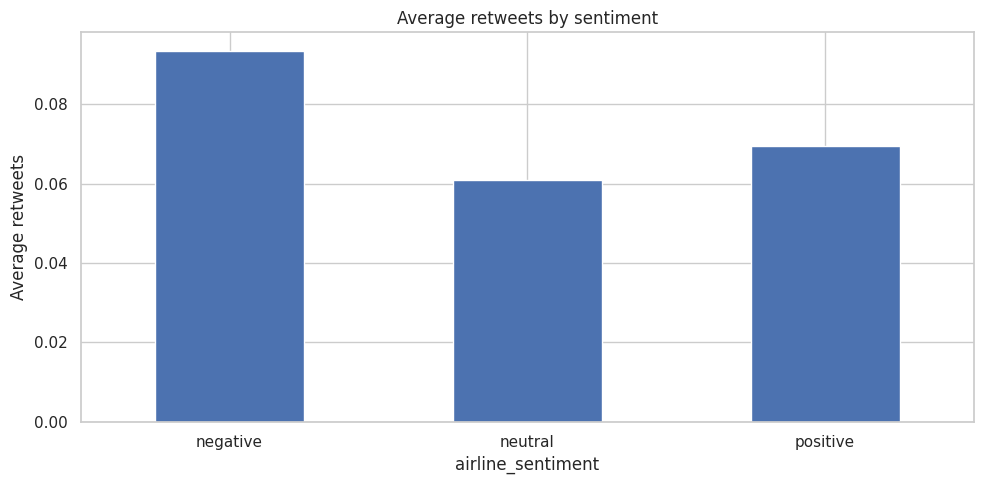

,airline,airline_sentiment,retweet_count,text
11596,US Airways,negative,44,@USAirways 5 hr flight delay and a delay when ...
11582,US Airways,negative,32,@USAirways of course never again tho . Thanks ...
7132,Delta,negative,31,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY....
9999,US Airways,neutral,28,@USAirways with this livery back in the day. h...
7115,Delta,negative,22,can you not? RT @JetBlue Our fleet's on fleek....
5607,Southwest,positive,22,@SouthwestAir beautiful day in Seattle! http:/...
7027,Delta,negative,18,"Just in case you needed confirmation that ""on ..."
7111,Delta,neutral,15,X____x RT @JetBlue: Our fleet's on fleek. http...
7453,Delta,positive,11,@JetBlue what a great experience on flight fro...
9453,US Airways,positive,9,@USAirways Wow unbelievable how you treat your...


Observation/evidence: compare mean, median and total retweets by sentiment above.
Why it matters: a smaller set of tweets may receive disproportionate attention.
Action: monitor and respond promptly to highly amplified negative posts.
Confidence/limits: retweets are not impressions and do not measure total passenger impact.


In [ ]:
retweet_summary=df.groupby("airline_sentiment")["retweet_count"].agg(["count","mean","median","sum"])
display(retweet_summary.round(2))
retweet_summary["mean"].plot.bar(title="Average retweets by sentiment",ylabel="Average retweets",rot=0); plt.tight_layout(); plt.show()
display(df.sort_values("retweet_count",ascending=False)[["airline","airline_sentiment","retweet_count","text"]].head(10))
print("Observation/evidence: compare mean, median and total retweets by sentiment above.")
print("Why it matters: a smaller set of tweets may receive disproportionate attention.")
print("Action: monitor and respond promptly to highly amplified negative posts.")
print("Confidence/limits: retweets are not impressions and do not measure total passenger impact.")

## Additional insight 2 – Concentration of negative reasons

,Count,Share of negative tweets
negativereason,,
Customer Service Issue,2910,0.317063
Late Flight,1665,0.181412
Can't Tell,1190,0.129658
Cancelled Flight,847,0.092286
Lost Luggage,724,0.078884
Bad Flight,580,0.063195
Flight Booking Problems,529,0.057638
Flight Attendant Complaints,481,0.052408
longlines,178,0.019394


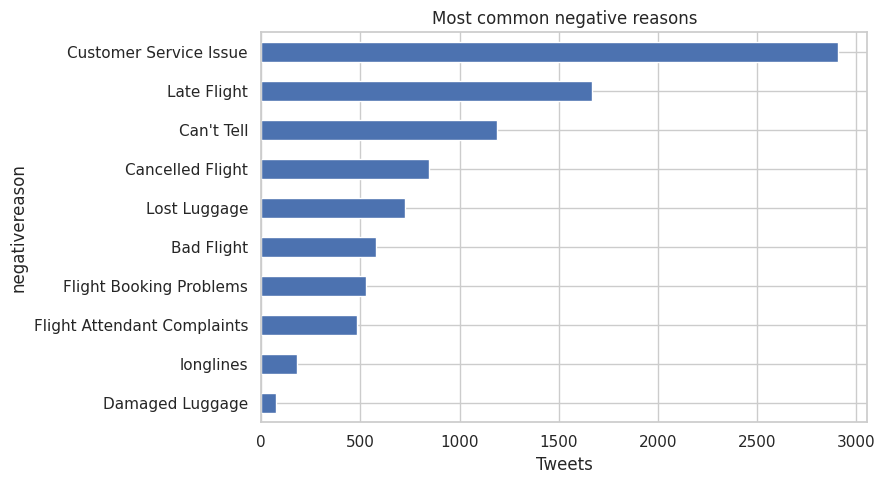

Observation: the highest-count reason is Customer Service Issue
Why it matters: concentrated reasons may offer a clear improvement target.
Action: investigate the largest category and validate it by reading original tweets.
Confidence/limits: reason labels may be missing or imperfect.


In [ ]:
reason_total=negative_df["negativereason"].value_counts()
display(pd.DataFrame({"Count":reason_total,"Share of negative tweets":reason_total/max(len(negative_df),1)}))
reason_total.head(12).sort_values().plot.barh(figsize=(9,5),title="Most common negative reasons")
plt.xlabel("Tweets"); plt.tight_layout(); plt.show()
print("Observation: the highest-count reason is",reason_total.index[0] if len(reason_total) else "unavailable")
print("Why it matters: concentrated reasons may offer a clear improvement target.")
print("Action: investigate the largest category and validate it by reading original tweets.")
print("Confidence/limits: reason labels may be missing or imperfect.")

## Additional insight 3 – Tweet length by sentiment

,count,mean,median
airline_sentiment,,,
negative,9178,18.05,19.0
neutral,3099,12.80,12.0
positive,2363,12.49,12.0


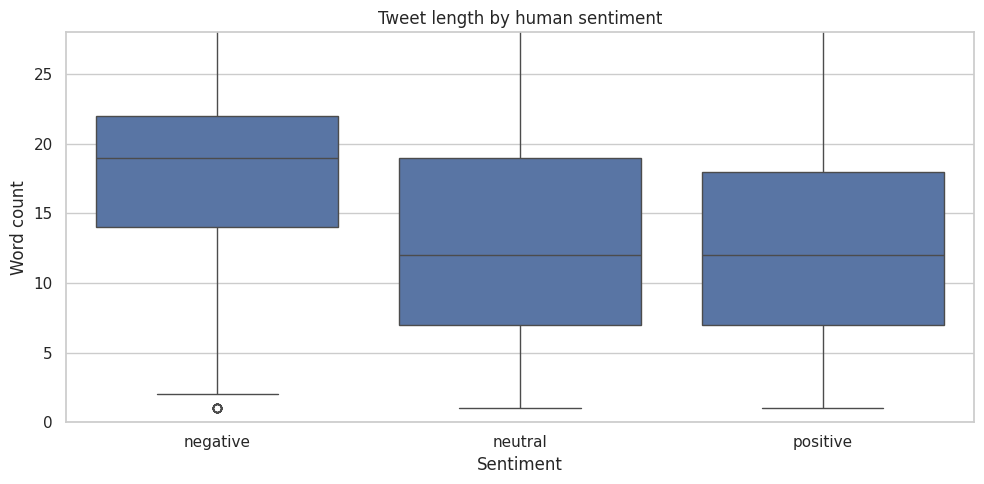

Observation/evidence: compare the median and spread of tweet length by sentiment.
Why it matters: longer posts may contain context or several issues.
Action: retain full text for complex complaints; do not use short keyword summaries alone.
Confidence/limits: length does not directly measure severity or passenger impact.


In [ ]:
df["tweet_word_count"]=df["text"].fillna("").apply(lambda x:len(tokenize(x)))
length_summary=df.groupby("airline_sentiment")["tweet_word_count"].agg(["count","mean","median"])
display(length_summary.round(2))
sns.boxplot(data=df,x="airline_sentiment",y="tweet_word_count",order=["negative","neutral","positive"])
plt.ylim(0,df["tweet_word_count"].quantile(.99))
plt.title("Tweet length by human sentiment"); plt.xlabel("Sentiment"); plt.ylabel("Word count"); plt.tight_layout(); plt.show()
print("Observation/evidence: compare the median and spread of tweet length by sentiment.")
print("Why it matters: longer posts may contain context or several issues.")
print("Action: retain full text for complex complaints; do not use short keyword summaries alone.")
print("Confidence/limits: length does not directly measure severity or passenger impact.")

# Director's one-page brief – generated from the dataset

In [ ]:
total=len(df); counts=df["airline_sentiment"].value_counts()
neg_count=int(counts.get("negative",0)); neg_share=neg_count/total
acc=accuracy_score(y,pred)
hardest=class_recall.idxmin()
top_share=airline_summary["Negative_share"].idxmax()
top_count=airline_summary["Negative_tweets"].idxmax()
top_reason=negative_df["negativereason"].value_counts().index[0]
print("="*65)
print("DIRECTOR'S CUSTOMER EXPERIENCE BRIEF")
print("="*65)
print(f"Dataset: {total:,} tweets across {df['airline'].nunique()} airlines.")
print(f"Human-labelled negative tweets: {neg_count:,} ({neg_share:.1%}).")
print(f"Most common recorded negative reason: {top_reason}.")
print(f"Highest negative share: {top_share} ({airline_summary.loc[top_share,'Negative_share']:.1%}).")
print(f"Highest raw negative count: {top_count} ({int(airline_summary.loc[top_count,'Negative_tweets']):,}).")
print(f"VADER overall accuracy: {acc:.1%}; lowest-recall class: {hardest}.")
print("\\nRECOMMENDATIONS")
print("1. Report negative share and raw count together.")
print("2. Prioritize high-confidence operational complaints and widely amplified posts.")
print("3. Use VADER for triage, not as a full replacement for human reading.")
print("4. Validate themes with original tweets and collect newer data before current decisions.")
print("\\nLIMITATIONS")
print("Twitter is a non-random sample; this file covers a short period in 2015. Findings do not establish causation.")
print("="*65)

DIRECTOR'S CUSTOMER EXPERIENCE BRIEF
Dataset: 14,640 tweets across 6 airlines.
Human-labelled negative tweets: 9,178 (62.7%).
Most common recorded negative reason: Customer Service Issue.
Highest negative share: US Airways (77.7%).
Highest raw negative count: United (2,633).
VADER overall accuracy: 49.0%; lowest-recall class: neutral.
\nRECOMMENDATIONS
1. Report negative share and raw count together.
2. Prioritize high-confidence operational complaints and widely amplified posts.
3. Use VADER for triage, not as a full replacement for human reading.
4. Validate themes with original tweets and collect newer data before current decisions.
\nLIMITATIONS
Twitter is a non-random sample; this file covers a short period in 2015. Findings do not establish causation.


## Export supporting tables

In [ ]:
cleaning_cost.to_csv("cleaning_cost_comparison.csv",index=False)
airline_summary.to_csv("airline_sentiment_summary.csv")
reason_counts.to_csv("airline_complaint_reason_counts.csv")
disagreements.to_csv("vader_human_disagreements.csv",index=False)
print("Saved four CSV analysis tables to the Colab working directory.")
print("Notebook submission: download this .ipynb. The manual also specifies a Python file; in Colab use File > Download > Download .py if required.")

Saved four CSV analysis tables to the Colab working directory.
Notebook submission: download this .ipynb. The manual also specifies a Python file; in Colab use File > Download > Download .py if required.
